# Frequentist A/B and experiment diagnostics

Assignment defines the comparison. The full-data Lin model includes all treatment interactions; adjusted and unadjusted SEs share the HC2 convention. Count simulations sample the released finite population without replacement.

Results are loaded from the saved analysis outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / 'results/full-run'
def table(name):
    frame = pd.read_csv(RESULTS / name)
    for column in frame.columns:
        if column == "two_sided_p_value":
            frame[column] = frame[column].map(lambda x: "< 1e-300" if x < 1e-300 else format(x, ".3g"))
        elif column.startswith("expected_loss_"):
            frame[column] = frame[column].map(lambda x: format(x, ".3e"))
    display(frame)
def figure(name):
    display(Image(filename=str(RESULTS / "figures" / name)))
def record(name):
    return json.loads((RESULTS / name).read_text())


,outcome,control_n,treatment_n,control_events,treatment_events,control_rate,treatment_rate,difference,standard_error,hc2_standard_error,pooled_z,two_sided_p_value,relative_lift,relative_lift_standard_error,approximate_mde_80pct_absolute,ci_low,ci_high,relative_lift_ci_low,relative_lift_ci_high
0,visit,2096937,11882655,80105,576824,0.038201,0.048543,0.010342,0.000146,0.000146,65.247430,< 1e-300,0.270737,0.004696,0.000402,0.010056,0.010629,0.261533,0.279941
1,conversion,2096937,11882655,4063,36711,0.001938,0.003089,0.001152,0.000034,0.000034,28.516529,7.31e-179,0.594488,0.026336,0.000092,0.001085,0.001219,0.542871,0.646105


,outcome,n,tau_adjusted,se_adjusted,tau_adj,se_adj,ci_low,ci_high,tau_unadjusted,se_unadjusted_hc2,unadjusted_ci_low,unadjusted_ci_high,se_ratio,adjusted_mean_control,adjusted_mean_treated,arm_hc2_variances,arm_residual_sums_of_squares
0,visit,13979592,0.007734,0.000131,0.007734,0.000131,0.007477,0.007991,0.010342,0.000146,0.010056,0.010629,0.897074,0.040286,0.048020,"[1.4497952793819062e-08, 2.730356966669244e-09]","[57645.60508588486, 392323.96222494415]"
1,conversion,13979592,0.001002,0.000034,0.001002,0.000034,0.000935,0.001068,0.001152,0.000034,0.001085,0.001219,0.988528,0.002050,0.003052,"[9.320817353879514e-10, 2.223804530078397e-10]","[3606.7650869230324, 32174.061431838345]"


,outcome,method,rejection_rate,mc_low,mc_high,repetitions
0,visit,A/A complementary control halves,0.055,0.042497,0.070908,1000
1,visit,Fixed final look,0.042,0.031221,0.056284,1000
2,visit,Any naive peeking look,0.301,0.273376,0.330147,1000
3,conversion,A/A complementary control halves,0.048,0.036393,0.063066,1000
4,conversion,Fixed final look,0.066,0.052212,0.083109,1000
5,conversion,Any naive peeking look,0.361,0.331816,0.391248,1000


,outcome,total_n,control_n,treatment_n,reference_control_rate,reference_treatment_rate,reference_difference,empirical_power,empirical_power_mc_low,empirical_power_mc_high,approximate_analytic_power,approximate_finite_population_power,control_variance_fpc,treatment_variance_fpc,approximate_mde80_absolute,approximate_mde80_relative
0,visit,10000,1500,8500,0.038201,0.048543,0.010342,0.390,0.348241,0.433436,0.407993,0.407960,0.999285,0.999285,0.015039,0.393689
1,visit,100000,15000,85000,0.038201,0.048543,0.010342,1.000,0.992376,1.000000,0.999942,0.999945,0.992847,0.992847,0.004756,0.124496
2,visit,1000000,150000,850000,0.038201,0.048543,0.010342,1.000,0.992376,1.000000,1.000000,1.000000,0.928468,0.928467,0.001504,0.039369
3,conversion,10000,1500,8500,0.001938,0.003089,0.001152,0.068,0.049067,0.093521,0.080399,0.080322,0.999285,0.999285,0.003450,1.780725
4,conversion,100000,15000,85000,0.001938,0.003089,0.001152,0.718,0.677012,0.755664,0.702307,0.702968,0.992847,0.992847,0.001091,0.563115
5,conversion,1000000,150000,850000,0.001938,0.003089,0.001152,1.000,0.992376,1.000000,1.000000,1.000000,0.928468,0.928467,0.000345,0.178073


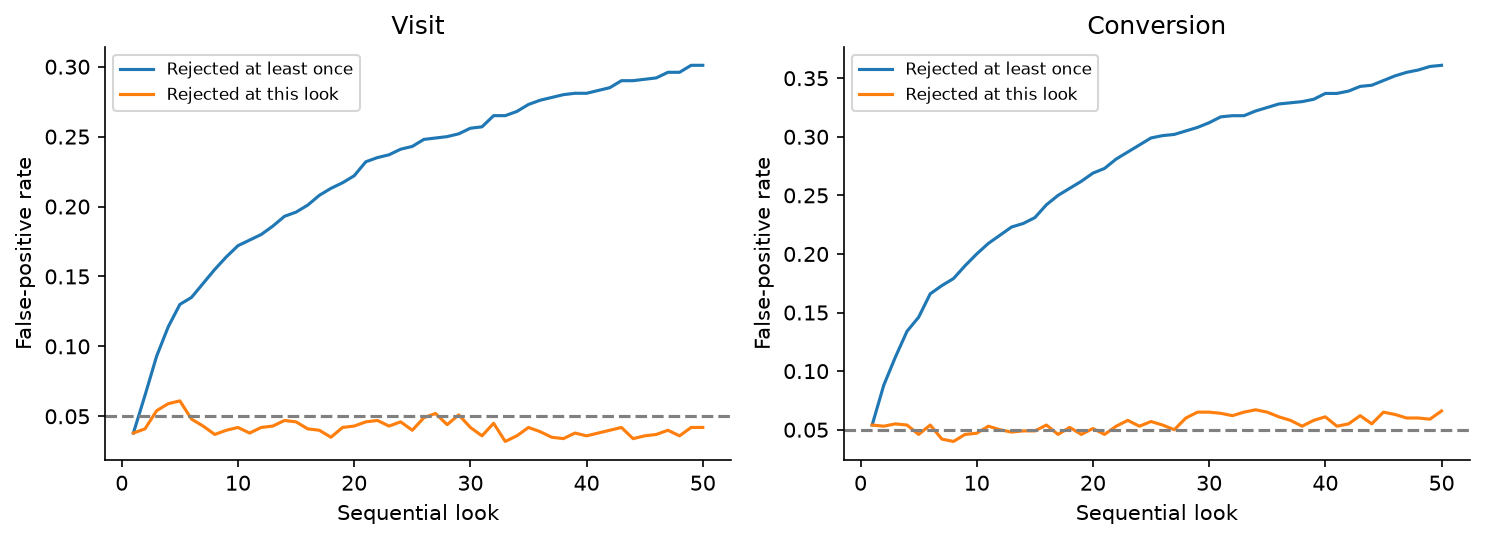

In [2]:
table("frequentist.csv")
table("adjustment.csv")
table("aa_peeking.csv")
table("power.csv")
figure("peeking.png")

In [3]:
m = record("manifest.json")
display({k: m[k] for k in ["git", "data_sha256", "seeds", "hardware"]})

{'git': {'commit': '6928958aac539e9314c5d992203a826e9d1e5037',
  'source': 'local_repository',
  'working_tree_dirty': False,
  'release_source_matches': True},
 'data_sha256': '2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc',
 'seeds': {'analysis': 2026,
  'simulation_root': 2026,
  'split': 2026,
  'lightgbm': 2026,
  'targeting_tie_break': 2026,
  'uplift_row_bootstrap': 2027},
 'hardware': {'os': 'macOS-26.6.2-arm64-arm-64bit',
  'architecture': 'arm64',
  'cpu': 'Apple M4',
  'physical_cores': 10,
  'logical_cores': 10,
  'ram_bytes': 17179869184,
  'python': '3.12.14'}}